In [28]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [29]:
dataset = pd.read_csv('Mall_Customers.csv')

In [30]:
dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [31]:
X = dataset.iloc[:, 3:5].values

In [32]:
X

array([[ 15,  39],
       [ 15,  81],
       [ 16,   6],
       [ 16,  77],
       [ 17,  40],
       [ 17,  76],
       [ 18,   6],
       [ 18,  94],
       [ 19,   3],
       [ 19,  72],
       [ 19,  14],
       [ 19,  99],
       [ 20,  15],
       [ 20,  77],
       [ 20,  13],
       [ 20,  79],
       [ 21,  35],
       [ 21,  66],
       [ 23,  29],
       [ 23,  98],
       [ 24,  35],
       [ 24,  73],
       [ 25,   5],
       [ 25,  73],
       [ 28,  14],
       [ 28,  82],
       [ 28,  32],
       [ 28,  61],
       [ 29,  31],
       [ 29,  87],
       [ 30,   4],
       [ 30,  73],
       [ 33,   4],
       [ 33,  92],
       [ 33,  14],
       [ 33,  81],
       [ 34,  17],
       [ 34,  73],
       [ 37,  26],
       [ 37,  75],
       [ 38,  35],
       [ 38,  92],
       [ 39,  36],
       [ 39,  61],
       [ 39,  28],
       [ 39,  65],
       [ 40,  55],
       [ 40,  47],
       [ 40,  42],
       [ 40,  42],
       [ 42,  52],
       [ 42,  60],
       [ 43,

In [33]:
from sklearn.mixture import GaussianMixture
X = np.random.RandomState(42).rand(100, 2)
num_clusters_list = []
n_components_range = range(1, 11)

for n_components in n_components_range:
    gmm_clusterer = GaussianMixture(n_components=n_components,random_state=42)
    gmm_clusterer.fit(X)
    num_clusters = len(np.unique(gmm_clusterer.predict(X)))
    num_clusters_list.append(num_clusters)

C:\Anaconda 3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Anaconda 3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Anaconda 3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Anaconda 3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than 

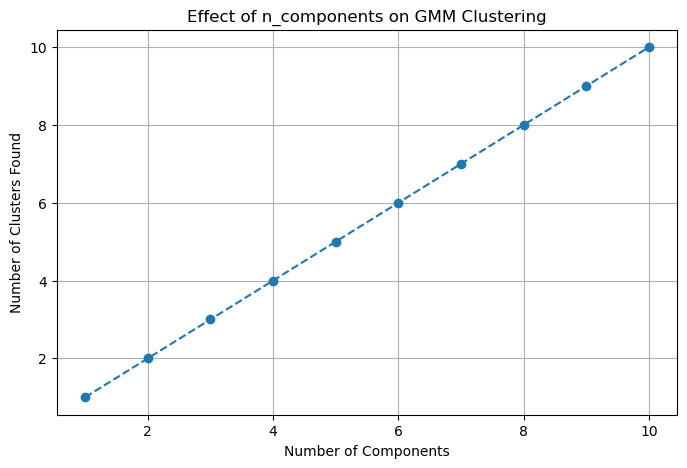

In [34]:
plt.figure(figsize=(8, 5))
plt.plot(
    list(n_components_range), num_clusters_list,marker="o",linestyle="--")
plt.title("Effect of n_components on GMM Clustering")
plt.xlabel("Number of Components")
plt.ylabel("Number of Clusters Found")
plt.grid(True)
plt.show()

In [35]:
num_clusters_list

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [36]:
from sklearn.datasets import make_blobs
X, _ = make_blobs(n_samples=200,centers=4,cluster_std=0.60,random_state=42)
gmm_clusterer = GaussianMixture(n_components=4,random_state=42)
gmm_clusterer.fit(X)
y_gmm = gmm_clusterer.predict(X)
print("Cluster labels:\n", y_gmm)

Cluster labels:
 [0 1 3 3 2 2 0 3 0 2 2 0 0 2 2 2 1 3 2 2 2 2 3 1 3 1 1 2 1 0 2 2 3 3 1 0 3
 0 3 1 2 1 2 2 3 0 0 2 0 1 3 1 3 0 1 1 2 2 1 0 3 0 2 3 3 2 0 1 3 1 1 3 1 2
 0 2 0 1 2 1 1 0 2 3 3 3 3 1 0 3 2 1 0 0 0 3 1 0 2 1 3 3 1 2 1 0 3 2 2 3 0
 2 1 3 1 3 3 1 1 1 3 2 0 3 3 0 1 0 0 1 2 2 1 3 3 0 2 2 1 2 0 1 3 0 0 1 0 3
 2 2 1 3 0 3 2 3 3 0 0 0 1 0 0 3 1 2 0 0 2 0 3 1 2 2 0 2 0 1 1 2 1 2 3 3 3
 1 0 0 0 1 1 2 3 3 1 3 0 1 2 0]


C:\Anaconda 3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [37]:
supervised=dataset

In [38]:
supervised['Cluster_group'] = y_gmm

In [39]:
supervised

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster_group
0,1,Male,19,15,39,0
1,2,Male,21,15,81,1
2,3,Female,20,16,6,3
3,4,Female,23,16,77,3
4,5,Female,31,17,40,2
...,...,...,...,...,...,...
195,196,Female,35,120,79,3
196,197,Female,45,126,28,0
197,198,Male,32,126,74,1
198,199,Male,32,137,18,2


In [40]:
supervised.to_csv("cluster_GMM_Clustering.csv", index=False)

In [41]:
supervised

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster_group
0,1,Male,19,15,39,0
1,2,Male,21,15,81,1
2,3,Female,20,16,6,3
3,4,Female,23,16,77,3
4,5,Female,31,17,40,2
...,...,...,...,...,...,...
195,196,Female,35,120,79,3
196,197,Female,45,126,28,0
197,198,Male,32,126,74,1
198,199,Male,32,137,18,2


In [42]:
dir(GaussianMixture)

['__abstractmethods__',
 '__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__sklearn_clone__',
 '__sklearn_tags__',
 '__slotnames__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abc_impl',
 '_build_request_for_signature',
 '_check_feature_names',
 '_check_n_features',
 '_check_parameters',
 '_compute_lower_bound',
 '_doc_link_module',
 '_doc_link_template',
 '_doc_link_url_param_generator',
 '_e_step',
 '_estimate_log_prob',
 '_estimate_log_prob_resp',
 '_estimate_log_weights',
 '_estimate_weighted_log_prob',
 '_estimator_type',
 '_get_default_requests',
 '_get_doc_link',
 '_get_metadata_request',
 '_get_param_na

In [43]:
cluster_centers = []
for label in np.unique(y_gmm):
    cluster_points = X[y_gmm == label]
    cluster_center = np.mean(cluster_points, axis=0)
    cluster_centers.append(cluster_center)
cluster_centers = np.array(cluster_centers)
print("Cluster Centers:\n", cluster_centers)

Cluster Centers:
 [[ 4.60639759  2.07515451]
 [-2.62455845  8.94744168]
 [-6.80424841 -6.88571308]
 [-8.7850371   7.37403591]]


In [44]:
y_gmm

array([0, 1, 3, 3, 2, 2, 0, 3, 0, 2, 2, 0, 0, 2, 2, 2, 1, 3, 2, 2, 2, 2,
       3, 1, 3, 1, 1, 2, 1, 0, 2, 2, 3, 3, 1, 0, 3, 0, 3, 1, 2, 1, 2, 2,
       3, 0, 0, 2, 0, 1, 3, 1, 3, 0, 1, 1, 2, 2, 1, 0, 3, 0, 2, 3, 3, 2,
       0, 1, 3, 1, 1, 3, 1, 2, 0, 2, 0, 1, 2, 1, 1, 0, 2, 3, 3, 3, 3, 1,
       0, 3, 2, 1, 0, 0, 0, 3, 1, 0, 2, 1, 3, 3, 1, 2, 1, 0, 3, 2, 2, 3,
       0, 2, 1, 3, 1, 3, 3, 1, 1, 1, 3, 2, 0, 3, 3, 0, 1, 0, 0, 1, 2, 2,
       1, 3, 3, 0, 2, 2, 1, 2, 0, 1, 3, 0, 0, 1, 0, 3, 2, 2, 1, 3, 0, 3,
       2, 3, 3, 0, 0, 0, 1, 0, 0, 3, 1, 2, 0, 0, 2, 0, 3, 1, 2, 2, 0, 2,
       0, 1, 1, 2, 1, 2, 3, 3, 3, 1, 0, 0, 0, 1, 1, 2, 3, 3, 1, 3, 0, 1,
       2, 0])

In [45]:
supervised.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)', 'Cluster_group'],
      dtype='object')

C:\Anaconda 3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


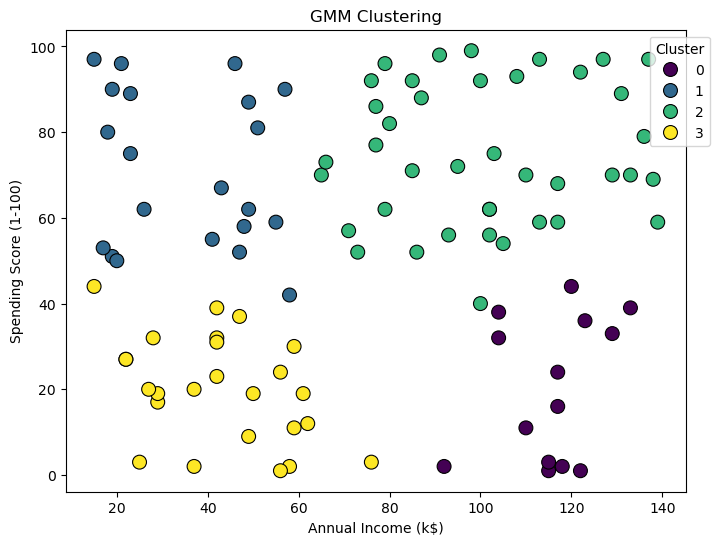

In [46]:
import seaborn as sns
np.random.seed(42)
supervised = pd.DataFrame({
    'CustomerID': np.arange(1, 101),
    'Age': np.random.randint(18, 70, 100),
    'Annual Income (k$)': np.random.randint(15, 140, 100),
    'Spending Score (1-100)': np.random.randint(1, 100, 100)
})
x_col = 'Annual Income (k$)'
y_col = 'Spending Score (1-100)'

gmm_clusterer = GaussianMixture(n_components=4,random_state=42)
supervised['Cluster'] = gmm_clusterer.fit_predict(supervised[[x_col, y_col]])
plt.figure(figsize=(8, 6))

sns.scatterplot(data=supervised,x=x_col,y=y_col,hue='Cluster',palette='viridis',s=100,edgecolor='k')
plt.title('GMM Clustering')
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.legend(title='Cluster',loc='best',bbox_to_anchor=(1.05, 1))
plt.show()

In [47]:
import pickle
with open("finalized_model_GMM.sav", "wb") as file:
    pickle.dump(gmm_clusterer, file)
print("GMM model saved successfully!")

GMM model saved successfully!


In [48]:
with open("finalized_model_GMM.sav", "rb") as file:
    loaded_model = pickle.load(file)
print("GMM model loaded successfully!")

GMM model loaded successfully!


In [49]:
new_data = pd.DataFrame({'Annual Income (k$)': [85],'Spending Score (1-100)': [75]})
prediction = loaded_model.predict(new_data)
print("Predicted Cluster:", prediction[0])

Predicted Cluster: 2
